# Results analysis: architecture study and ablations

This notebook reproduces every table and figure of the **design-exploration** part of the report
(Section 4) from the raw training records. It needs only a CPU (no training happens here).

Inputs (all written automatically by the training notebook `training_notebook.ipynb`):

* `experiments.csv`: one row per run (config, parameter count, final / best validation accuracy, time).
* `logs/<run>/log.csv`: per-epoch training loss / accuracy and validation loss / accuracy.

Kaggle public-leaderboard scores are not produced by code; they were copied from the competition
page after each submission and are entered by hand in the cell below.

All validation numbers use the same stratified 45,000 / 5,000 split (500 images per class, seed 42).
The test set was never used for training, validation, or model selection.

In [1]:
import json, os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option('display.width', 160)

# Fixed colours (categorical slots 1-3 + neutral)
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#52514e', 'savefig.bbox': 'tight', 'savefig.dpi': 200})

## 1. All runs

In [2]:
exp = pd.read_csv('experiments.csv')
cfg = exp['config'].apply(json.loads)
exp['channels'] = cfg.apply(lambda c: tuple(c['channels']))
exp['blocks']   = cfg.apply(lambda c: tuple(c['blocks']))
exp['full']     = cfg.apply(lambda c: c.get('full_train', False))

# Kaggle public leaderboard (1,000 images), copied by hand from the competition page.
KAGGLE = {
    'v1_baseline': 0.824, 'v2_blur_noise': 0.809, 'v3_80epochs': 0.848, 'v4_ls_cutout': 0.838,
    'v5b_trivialaug_150ep': 0.873, 'final_full_C': 0.878, 'arch_C_300ep': 0.889,
    'arch_C_300ep_cutmix': 0.885, 'final_full_C_400ep': 0.883,
}
exp['kaggle_public'] = exp['run_name'].map(KAGGLE)

view = exp[['run_name', 'params', 'channels', 'blocks', 'epochs', 'full',
            'val_acc', 'val_acc_tta', 'best_val_acc', 'kaggle_public', 'minutes']].copy()
for c in ['val_acc', 'val_acc_tta', 'best_val_acc']:
    view[c] = (100 * view[c]).round(2)
print('Every model is under the 5M limit:', bool((exp['params'] <= 5_000_000).all()))
view

Every model is under the 5M limit: True


,run_name,params,channels,blocks,epochs,full,val_acc,val_acc_tta,best_val_acc,kaggle_public,minutes
0,v1_baseline,4977226,"(64, 128, 256, 512)","(2, 1, 1, 1)",30,False,93.26,93.62,NaN,0.824,6.3
1,v2_blur_noise,4977226,"(64, 128, 256, 512)","(2, 1, 1, 1)",30,False,92.88,93.28,NaN,0.809,6.3
2,v3_80epochs,4977226,"(64, 128, 256, 512)","(2, 1, 1, 1)",80,False,94.28,94.54,NaN,0.848,17.0
3,v4_ls_cutout,4977226,"(64, 128, 256, 512)","(2, 1, 1, 1)",80,False,95.08,95.26,NaN,0.838,17.2
4,v5a_trivialaug,4977226,"(64, 128, 256, 512)","(2, 1, 1, 1)",80,False,94.88,95.06,94.90,NaN,17.0
5,v5b_trivialaug_150ep,4977226,"(64, 128, 256, 512)","(2, 1, 1, 1)",150,False,95.66,96.12,95.74,0.873,31.3
6,final_full_v5b,4977226,"(64, 128, 256, 512)","(2, 1, 1, 1)",150,True,99.54,99.60,99.54,NaN,35.3
7,arch_B_deep_narrow,4815940,"(42, 84, 168, 336)","(2, 2, 2, 2)",80,False,94.72,95.22,94.78,NaN,18.9
8,arch_C_wide_3stage,4781374,"(84, 168, 336)","(2, 2, 2)",80,False,95.58,95.84,95.64,NaN,37.3
9,arch_C_150ep,4781374,"(84, 168, 336)","(2, 2, 2)",150,False,96.32,96.50,96.44,NaN,69.7


## 2. Architecture definitions and parameter / compute budget

The same `ResNet` class as in the training notebook. Architecture **A** = 4 stages (64,128,256,512)
with (2,1,1,1) blocks; **B** = deeper / narrower, 4 stages (42,84,168,336) with (2,2,2,2) blocks;
**C** = 3 wide stages (84,168,336) with (2,2,2) blocks, so the last stage works at 8x8 instead of 4x4.
`WideResNet` is a copy of `src/model.py` from the main repository (final submission model).

In [3]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = (nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride, bias=False), nn.BatchNorm2d(out_ch))
                         if stride != 1 or in_ch != out_ch else nn.Identity())
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))

class ResNet(nn.Module):
    def __init__(self, channels, blocks, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, channels[0], 3, 1, 1, bias=False),
                                  nn.BatchNorm2d(channels[0]), nn.ReLU(inplace=True))
        layers, in_ch = [], channels[0]
        for i, (ch, n) in enumerate(zip(channels, blocks)):
            for j in range(n):
                layers.append(BasicBlock(in_ch, ch, 2 if (i > 0 and j == 0) else 1)); in_ch = ch
        self.layers = nn.Sequential(*layers)
        self.fc = nn.Linear(in_ch, num_classes)
    def forward(self, x):
        return self.fc(F.adaptive_avg_pool2d(self.layers(self.stem(x)), 1).flatten(1))

class WideBlock(nn.Module):  # pre-activation block, copied from src/model.py
    def __init__(self, i, o, stride=1, dropout=0.0):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(i); self.conv1 = nn.Conv2d(i, o, 3, stride, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(o); self.conv2 = nn.Conv2d(o, o, 3, padding=1, bias=False)
        self.shortcut = nn.Identity() if i == o and stride == 1 else nn.Conv2d(i, o, 1, stride, bias=False)
        self.dropout = dropout
    def forward(self, x):
        pre = F.relu(self.bn1(x))
        skip = x if isinstance(self.shortcut, nn.Identity) else self.shortcut(pre)
        out = F.relu(self.bn2(self.conv1(pre)))
        return skip + self.conv2(F.dropout(out, self.dropout, self.training))

class WideResNet(nn.Module):
    def __init__(self, depth=28, base_width=56, num_classes=10):
        super().__init__()
        n = (depth - 4) // 6
        self.stem = nn.Conv2d(3, 16, 3, padding=1, bias=False)
        blocks, prev = [], 16
        for s, w in enumerate([base_width, 2 * base_width, 4 * base_width]):
            for b in range(n):
                blocks.append(WideBlock(prev, w, 2 if s > 0 and b == 0 else 1)); prev = w
        self.blocks = nn.Sequential(*blocks)
        self.bn = nn.BatchNorm2d(prev); self.head = nn.Linear(prev, num_classes)
    def forward(self, x):
        x = F.relu(self.bn(self.blocks(self.stem(x))))
        return self.head(F.adaptive_avg_pool2d(x, 1).flatten(1))

def budget(model):
    """Trainable params, multiply-accumulates per image, and share of params per spatial resolution."""
    macs, by_res = [0], {}
    def hook(m, inp, out):
        if isinstance(m, nn.Conv2d):
            k = m.weight.numel() // m.out_channels      # in/groups * kh * kw
            macs[0] += k * out.numel()
            res = out.shape[-1]
            by_res[res] = by_res.get(res, 0) + sum(p.numel() for p in m.parameters())
        elif isinstance(m, nn.Linear):
            macs[0] += m.weight.numel()
    hs = [m.register_forward_hook(hook) for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    model.eval();
    with torch.no_grad(): model(torch.zeros(1, 3, 32, 32))
    for h in hs: h.remove()
    total = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, macs[0], by_res

ARCHS = {
    'A (4 stages, 64-512)':        ResNet((64, 128, 256, 512), (2, 1, 1, 1)),
    'B (4 stages, deep/narrow)':   ResNet((42, 84, 168, 336), (2, 2, 2, 2)),
    'C (3 wide stages)':           ResNet((84, 168, 336), (2, 2, 2)),
    'WRN-28-56 (final submission)': WideResNet(28, 56),
}
rows = []
for name, m in ARCHS.items():
    total, macs, by_res = budget(m)
    conv = sum(by_res.values())
    rows.append(dict(model=name, params=f'{total:,}', under_5M=total <= 5_000_000, MMACs=round(macs / 1e6),
                     final_res=f'{min(by_res)}x{min(by_res)}',
                     **{f'conv params @{r}x{r} (%)': round(100 * v / conv, 1) for r, v in sorted(by_res.items(), reverse=True)}))
budget_df = pd.DataFrame(rows).fillna('-')
budget_df

,model,params,under_5M,MMACs,final_res,conv params @32x32 (%),conv params @16x16 (%),conv params @8x8 (%),conv params @4x4 (%)
0,"A (4 stages, 64-512)","4,977,226",True,329,4x4,3.0,4.6,18.5,73.9
1,"B (4 stages, deep/narrow)","4,815,940",True,240,4x4,1.3,4.7,18.8,75.2
2,C (3 wide stages),"4,781,374",True,725,8x8,5.4,18.9,75.7,-
3,WRN-28-56 (final submission),"4,480,474",True,649,8x8,4.6,19.1,76.3,-


## 3. Architecture comparison at an equal budget (80 epochs, identical recipe)

In [4]:
LOGS = {'A': 'v5a_trivialaug', 'B': 'arch_B_deep_narrow', 'C': 'arch_C_wide_3stage'}
logs = {k: pd.read_csv(f'logs/{v}/log.csv') for k, v in LOGS.items()}
e = exp.set_index('run_name')
arch_tab = pd.DataFrame([{
    'arch': k, 'run': v, 'params': int(e.loc[v, 'params']),
    'final val (%)': round(100 * e.loc[v, 'val_acc'], 2),
    'final val + flip TTA (%)': round(100 * e.loc[v, 'val_acc_tta'], 2),
    'best val (%)': round(100 * e.loc[v, 'best_val_acc'], 2),
    'mean val, last 5 epochs (%)': round(100 * logs[k]['val_acc'].tail(5).mean(), 2),
} for k, v in LOGS.items()])
arch_tab

,arch,run,params,final val (%),final val + flip TTA (%),best val (%),"mean val, last 5 epochs (%)"
0,A,v5a_trivialaug,4977226,94.88,95.06,94.90,94.75
1,B,arch_B_deep_narrow,4815940,94.72,95.22,94.78,94.68
2,C,arch_C_wide_3stage,4781374,95.58,95.84,95.64,95.53


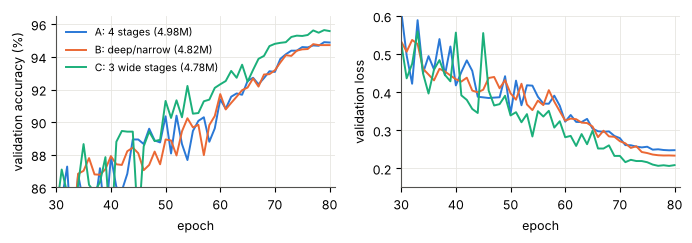

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.5))
cols = {'A': BLUE, 'B': ORANGE, 'C': AQUA}
labels = {'A': 'A: 4 stages (4.98M)', 'B': 'B: deep/narrow (4.82M)', 'C': 'C: 3 wide stages (4.78M)'}
for k, d in logs.items():
    axes[0].plot(d['epoch'], 100 * d['val_acc'], color=cols[k], lw=1.4, label=labels[k])
    axes[1].plot(d['epoch'], d['val_loss'], color=cols[k], lw=1.4, label=labels[k])
axes[0].set_ylim(86, 96.5); axes[0].set_xlim(30, 81); axes[0].set_ylabel('validation accuracy (%)')
axes[1].set_ylim(0.15, 0.6); axes[1].set_xlim(30, 81); axes[1].set_ylabel('validation loss')
for ax in axes: ax.set_xlabel('epoch')
axes[0].legend(frameon=False, loc='upper left', fontsize=7.5)
fig.tight_layout(); fig.savefig(f'{FIG_DIR}/fig_arch_curves.pdf'); fig.savefig(f'{FIG_DIR}/fig_arch_curves.png')
plt.show()

## 4. Training length (architecture C)

                    epochs  val_acc  val_acc_tta  best_val_acc  kaggle_public
run_name                                                                     
arch_C_wide_3stage      80    95.58        95.84         95.64            NaN
arch_C_150ep           150    96.32        96.50         96.44            NaN
arch_C_300ep           300    96.78        97.26         96.94          0.889


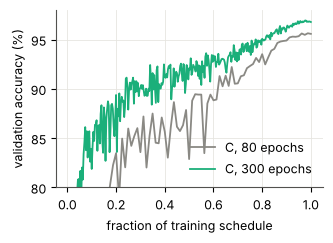

In [6]:
c300 = pd.read_csv('logs/arch_C_300ep/log.csv')
len_tab = e.loc[['arch_C_wide_3stage', 'arch_C_150ep', 'arch_C_300ep'],
                ['epochs', 'val_acc', 'val_acc_tta', 'best_val_acc', 'kaggle_public']].copy()
for c in ['val_acc', 'val_acc_tta', 'best_val_acc']: len_tab[c] = (100 * len_tab[c]).round(2)
print(len_tab)

fig, ax = plt.subplots(figsize=(3.4, 2.5))
ax.plot(logs['C']['epoch'] / 80, 100 * logs['C']['val_acc'], color=GRAY, lw=1.3, label='C, 80 epochs')
ax.plot(c300['epoch'] / 300, 100 * c300['val_acc'], color=AQUA, lw=1.3, label='C, 300 epochs')
ax.set_ylim(80, 98); ax.set_xlabel('fraction of training schedule'); ax.set_ylabel('validation accuracy (%)')
ax.legend(frameon=False, loc='lower right')
fig.tight_layout(); fig.savefig(f'{FIG_DIR}/fig_epochs.pdf'); fig.savefig(f'{FIG_DIR}/fig_epochs.png')
plt.show()

## 5. Augmentation / regularisation ablations

Each row changes the recipe of the row it is compared with. `robust_acc` is the mean validation accuracy over
eight synthetic perturbations of the validation images (brightness, contrast, colour, 3x3 blur, Gaussian noise);
it was computed by the robustness cell of the training notebook.

In [7]:
ABL = ['v1_baseline', 'v2_blur_noise', 'v3_80epochs', 'v4_ls_cutout', 'v5a_trivialaug', 'v5b_trivialaug_150ep',
       'arch_C_300ep', 'arch_C_300ep_cutmix', 'arch_C_300ep_sam', 'arch_C_300ep_cutmix_bs128', 'arch_C_300ep_swa']
abl = e.loc[ABL, ['epochs', 'val_acc', 'val_acc_tta', 'robust_acc', 'kaggle_public', 'notes']].copy()
for c in ['val_acc', 'val_acc_tta', 'robust_acc']: abl[c] = (100 * abl[c]).round(2)
abl

,epochs,val_acc,val_acc_tta,robust_acc,kaggle_public,notes
run_name,,,,,,
v1_baseline,30,93.26,93.62,85.50,0.824,NaN
v2_blur_noise,30,92.88,93.28,91.67,0.809,NaN
v3_80epochs,80,94.28,94.54,NaN,0.848,NaN
v4_ls_cutout,80,95.08,95.26,85.62,0.838,NaN
v5a_trivialaug,80,94.88,95.06,91.22,NaN,NaN
v5b_trivialaug_150ep,150,95.66,96.12,92.47,0.873,NaN
arch_C_300ep,300,96.78,97.26,NaN,0.889,NaN
arch_C_300ep_cutmix,300,97.08,97.32,NaN,0.885,NaN
arch_C_300ep_sam,300,97.08,97.30,NaN,NaN,NaN


val(TTA) - Kaggle gap, percentage points: mean 10.1, min 8.4, max 12.4
Std. error of a 1,000-image accuracy near 89%: 1.0 points (95% CI +/- 1.9)


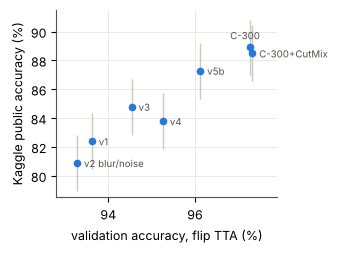

In [8]:
# Validation accuracy vs Kaggle public accuracy for every run with both numbers
both = exp.dropna(subset=['kaggle_public'])
both = both[~both['full']]
gap = 100 * (both['val_acc_tta'] - both['kaggle_public'])
print('val(TTA) - Kaggle gap, percentage points: mean %.1f, min %.1f, max %.1f' % (gap.mean(), gap.min(), gap.max()))
se = np.sqrt(0.89 * 0.11 / 1000)
print('Std. error of a 1,000-image accuracy near 89%%: %.1f points (95%% CI +/- %.1f)' % (100 * se, 196 * se))

fig, ax = plt.subplots(figsize=(3.4, 2.6))
ax.errorbar(100 * both['val_acc_tta'], 100 * both['kaggle_public'], yerr=196 * se, fmt='o', ms=4.5,
            color=BLUE, ecolor='#c9c8c2', elinewidth=1, capsize=0)
short = {'v1_baseline': 'v1', 'v2_blur_noise': 'v2 blur/noise', 'v3_80epochs': 'v3', 'v4_ls_cutout': 'v4',
         'v5b_trivialaug_150ep': 'v5b', 'arch_C_300ep': 'C-300', 'arch_C_300ep_cutmix': 'C-300+CutMix'}
for _, r in both.iterrows():
    ax.annotate(short.get(r['run_name'], r['run_name']), (100 * r['val_acc_tta'], 100 * r['kaggle_public']),
                textcoords='offset points', xytext=(-14, 6) if r['run_name'] == 'arch_C_300ep' else (5, -3),
                fontsize=7, color='#52514e')
ax.set_xlabel('validation accuracy, flip TTA (%)'); ax.set_ylabel('Kaggle public accuracy (%)')
ax.set_xlim(92.8, 97.9); ax.set_ylim(78.5, 91.5)
fig.tight_layout(); fig.savefig(f'{FIG_DIR}/fig_val_vs_kaggle.pdf'); fig.savefig(f'{FIG_DIR}/fig_val_vs_kaggle.png')
plt.show()

## 6. Test-time augmentation

Values printed by the TTA cells of the training notebook (validation set; Kaggle from the leaderboard).
10-view = original + 4 two-pixel shifts, each also flipped; 18-view adds the 4 one-pixel shifts.

In [9]:
tta = pd.DataFrame([
    dict(model='arch_C_300ep',        views='flip (2)',       val=97.26, kaggle=0.889),
    dict(model='arch_C_300ep',        views='flip + 2px (10)', val=97.38, kaggle=0.891),
    dict(model='arch_C_300ep_cutmix', views='flip (2)',       val=97.32, kaggle=0.885),
    dict(model='arch_C_300ep_cutmix', views='flip + 1&2px (18)', val=97.50, kaggle=0.886),
])
tta

,model,views,val,kaggle
0,arch_C_300ep,flip (2),97.26,0.889
1,arch_C_300ep,flip + 2px (10),97.38,0.891
2,arch_C_300ep_cutmix,flip (2),97.32,0.885
3,arch_C_300ep_cutmix,flip + 1&2px (18),97.50,0.886


## 7. Final numbers

In [10]:
best = e.loc['arch_C_300ep']
print(f"Best own model : arch_C_300ep | params {int(best['params']):,} | val {100*best['val_acc']:.2f}% "
      f"| val+flip TTA {100*best['val_acc_tta']:.2f}% | Kaggle public 0.889 (flip) / 0.891 (10-view TTA)")
print("Final submission (team): WRN-28-56 | params 4,480,474 | val (EMA, flip TTA) 97.36% | Kaggle public 0.897")

Best own model : arch_C_300ep | params 4,781,374 | val 96.78% | val+flip TTA 97.26% | Kaggle public 0.889 (flip) / 0.891 (10-view TTA)
Final submission (team): WRN-28-56 | params 4,480,474 | val (EMA, flip TTA) 97.36% | Kaggle public 0.897
